# Decision Tree Classifier: Predicting Violent Crime Levels

## Project Objective
Analyze Indian districts based on historical reported crime patterns using regression, classification, and clustering to identify comparatively lower/higher reported crime levels and groups of districts with similar crime profiles.

This notebook implements a **Decision Tree Classifier** to predict a district's `Violent Crime Level` (Low, Medium, or High) based entirely on its property and disturbance crimes.

## Step 1 — Data Loading and Preparation

Because our previously prepared variables (`X_train_clf`, etc.) were stored in the memory of the `data_prep.ipynb` notebook, we will quickly reproduce the exact same preprocessing steps here. 

We will:
1. Load the dataset and remove summary rows.
2. Create the `Violent Crime Score`.
3. Perform the Time-Based Split: Training (2001-2009) and Testing (2010-2012).
4. Calculate the Low/Medium/High tertile thresholds using **only** the training data.
5. Create our classification features and target variables without data leakage.

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
file_path = '../data/factors/crime/01_District_wise_crimes_committed_IPC_2001_2012.csv'
df = pd.read_csv(file_path)

# Filter summary rows
df_clean = df[~df['DISTRICT'].isin(['TOTAL', 'DELHI UT TOTAL'])].copy()

# Create Project-Defined Composite Score
df_clean['Violent Crime Score'] = (
    df_clean['MURDER'] + 
    df_clean['ATTEMPT TO MURDER'] + 
    df_clean['RAPE'] + 
    df_clean['KIDNAPPING & ABDUCTION']
)

# Time-Based Split
train_df = df_clean[df_clean['YEAR'] <= 2009].copy()
test_df = df_clean[df_clean['YEAR'] >= 2010].copy()

# Calculate classification thresholds from TRAINING data only
lower_threshold = train_df['Violent Crime Score'].quantile(0.33)
upper_threshold = train_df['Violent Crime Score'].quantile(0.67)

def categorize_crime(score):
    if score <= lower_threshold:
        return 'Low'
    elif score <= upper_threshold:
        return 'Medium'
    else:
        return 'High'

# Apply labels to both sets
train_df['Violent Crime Level'] = train_df['Violent Crime Score'].apply(categorize_crime)
test_df['Violent Crime Level'] = test_df['Violent Crime Score'].apply(categorize_crime)

# Define Features and Target
clf_features = ['THEFT', 'BURGLARY', 'ROBBERY', 'CHEATING', 'RIOTS']
clf_target = 'Violent Crime Level'

# Create final ML variables
X_train_clf = train_df[clf_features]
y_train_clf = train_df[clf_target]

X_test_clf = test_df[clf_features]
y_test_clf = test_df[clf_target]

print("Data preparation complete!")

Data preparation complete!


## Step 2 — Import ML Libraries

We import standard Data Science libraries for modeling, evaluating, and visualizing our classification results.

In [2]:
import matplotlib.pyplot as plt

# Import Decision Tree algorithm and visualizer
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 3 — What is a Decision Tree?

1. **What is a Decision Tree?** It is a Machine Learning algorithm that acts like a flowchart. It splits data by asking a series of Yes/No questions to arrive at a final prediction.
2. **What is Classification?** Unlike regression (which predicts a continuous number), classification predicts a category or label.
3. **What is a feature?** The input variables the tree uses to ask questions. We are using `THEFT`, `BURGLARY`, `ROBBERY`, `CHEATING`, and `RIOTS`.
4. **What is the target?** The label we are trying to predict: `Violent Crime Level` (Low, Medium, or High).
5. **How it makes decisions:** It looks for the feature that best separates the classes and creates a "rule". 
6. **What a leaf/node means:** A "node" is where a question is asked. A "leaf" is the absolute end of a branch, which holds the final prediction (Low, Medium, or High).
7. **Why they are easy to interpret:** Because we can literally draw the tree and read the exact rules it used, it is completely transparent.

### Simple Conceptual Example:
```text
Is THEFT <= 500?
        ↓
    Yes   No
     ↓     ↓
   Is ROBBERY <= 50?
           ↓
       Yes   No
        ↓     ↓
       Low   High
```

## Step 4 — Inspect the prepared data

Let's look at the shape and contents of our datasets before training.

In [3]:
# Display shapes
print(f"X_train_clf shape (Training): {X_train_clf.shape}")
print(f"X_test_clf shape (Testing):   {X_test_clf.shape}\n")

# Verify no missing values
print(f"Missing values in training features: {X_train_clf.isnull().sum().sum()}")
print(f"Missing values in testing features:  {X_test_clf.isnull().sum().sum()}\n")

# Display feature names
print("Features used:", list(X_train_clf.columns))

# Display class counts
print("\nTraining Class Counts:")
display(y_train_clf.value_counts())

print("\nTesting Class Counts:")
display(y_test_clf.value_counts())

print("\nFirst 5 rows of X_train_clf:")
display(X_train_clf.head())

X_train_clf shape (Training): (6321, 5)
X_test_clf shape (Testing):   (2276, 5)

Missing values in training features: 0
Missing values in testing features:  0

Features used: ['THEFT', 'BURGLARY', 'ROBBERY', 'CHEATING', 'RIOTS']

Training Class Counts:


Violent Crime Level
Medium    2137
Low       2102
High      2082
Name: count, dtype: int64


Testing Class Counts:


Violent Crime Level
High      900
Medium    716
Low       660
Name: count, dtype: int64


First 5 rows of X_train_clf:


,THEFT,BURGLARY,ROBBERY,CHEATING,RIOTS
0,199,198,41,104,78
1,366,191,16,65,168
2,723,237,14,209,156
3,173,98,4,37,164
4,1021,437,25,220,70


## Step 5 — Train the Decision Tree

We initialize the Decision Tree Classifier and train it using `.fit()`.

* `random_state=42`: This ensures that if the algorithm has to break a tie between two equally good splits, it will make the exact same choice every time you run the code, making our results reproducible.
* `max_depth=5`: This prevents the tree from growing deeper than 5 levels of questions. Without a limit, a decision tree will keep growing until it perfectly memorizes every single row in the training data, becoming a massive, unreadable mess that performs poorly on new data. A depth of 5 keeps the model simple, robust, and interpretable.

The `.fit()` command is where the algorithm analyzes the training data and automatically discovers the best Yes/No rules.

In [4]:
# Initialize the model
model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train the model
model.fit(X_train_clf, y_train_clf)

print("Decision Tree Classifier successfully trained!")

Decision Tree Classifier successfully trained!


## Step 6 — Make Predictions

We ask our trained model to look at the future test data (2010–2012 features) and predict the `Violent Crime Level`. We then place the model's predictions next to what actually happened.

In [5]:
# Use the trained model to predict the testing data
y_pred = model.predict(X_test_clf)

# Create a comparison dataframe
comparison_df = pd.DataFrame({
    'Actual': y_test_clf.values,
    'Predicted': y_pred
})

print("Comparison of Actual vs Predicted (First 15 observations):")
display(comparison_df.head(15))

Comparison of Actual vs Predicted (First 15 observations):


,Actual,Predicted
0,High,High
1,High,High
2,High,High
3,High,Medium
4,High,High
5,High,Medium
6,Low,Low
7,High,High
8,Medium,High
9,High,High


## Step 7 — Evaluate the Classifier

Because this is a classification problem, we don't calculate "errors" (like MSE). Instead, we calculate how often we were right. Because we have three classes (Low, Medium, High), we use "weighted" averages to account for slight imbalances in class sizes.

* **Accuracy:** The overall proportion of predictions that were exactly correct.
* **Precision:** When the model predicted "High", how often was it actually "High"?
* **Recall:** Out of all the actual "High" districts, how many did the model successfully find?
* **F1-score:** A balanced metric combining Precision and Recall.

In [6]:
# Calculate metrics
accuracy = accuracy_score(y_test_clf, y_pred)
precision = precision_score(y_test_clf, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test_clf, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test_clf, y_pred, average="weighted", zero_division=0)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Weighted Precision:{precision:.4f}")
print(f"Weighted Recall:   {recall:.4f}")
print(f"Weighted F1-score: {f1:.4f}\n")

print("Detailed Classification Report:")
print(classification_report(y_test_clf, y_pred, zero_division=0))

Accuracy:          0.6911
Weighted Precision:0.6956
Weighted Recall:   0.6911
Weighted F1-score: 0.6931

Detailed Classification Report:
              precision    recall  f1-score   support

        High       0.73      0.72      0.72       900
         Low       0.81      0.79      0.80       660
      Medium       0.54      0.57      0.56       716

    accuracy                           0.69      2276
   macro avg       0.70      0.69      0.69      2276
weighted avg       0.70      0.69      0.69      2276



## Step 8 — Confusion Matrix

A Confusion Matrix visually shows exactly what the model got right and what it confused.
* **Rows:** The actual true classes.
* **Columns:** The classes the model predicted.
* **Diagonal:** The correct predictions.
* **Off-Diagonal:** The mistakes (e.g., predicting "Low" when it was actually "High").

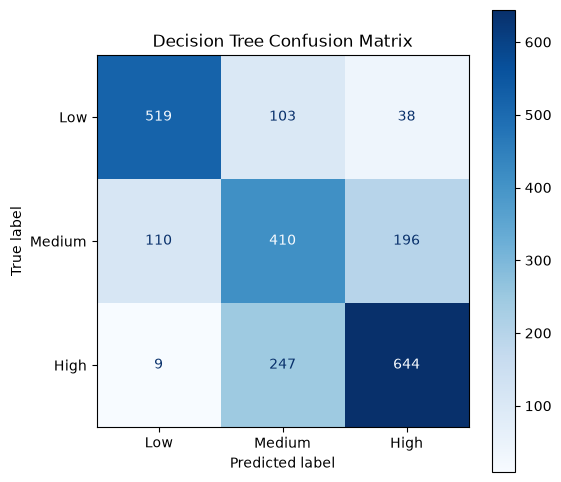

In [7]:
# Create the confusion matrix array
cm = confusion_matrix(
    y_test_clf,
    y_pred,
    labels=["Low", "Medium", "High"]
)

# Display it visually
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues')
plt.title("Decision Tree Confusion Matrix")
plt.grid(False)
plt.show()

## Step 9 — Feature Importance

Feature importance calculates how much each variable contributed to the tree's splitting decisions. 
*(IMPORTANT: A high importance score does not mean a crime causes another crime. It simply means this variable provided the best mathematical separation between Low, Medium, and High districts in our dataset).*

,Feature,Importance
0,ROBBERY,0.600423
1,CHEATING,0.163298
2,RIOTS,0.091081
3,THEFT,0.074365
4,BURGLARY,0.070833


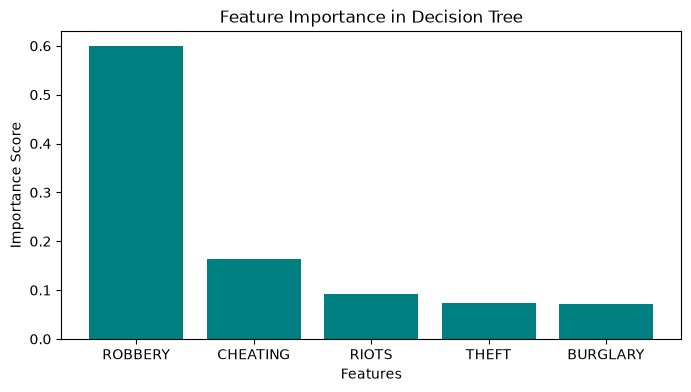

In [8]:
# Extract importances
importances = model.feature_importances_

# Create a dataframe
importance_df = pd.DataFrame({
    'Feature': clf_features,
    'Importance': importances
})

# Sort from highest to lowest
importance_df = importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

display(importance_df)

# Plot
plt.figure(figsize=(8, 4))
plt.bar(importance_df['Feature'], importance_df['Importance'], color='teal')
plt.title('Feature Importance in Decision Tree')
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.show()

## Step 10 — Visualize the Decision Tree

Here we can see the exact rules the model learned.
* **Top box (Root Node):** The very first, most important question the tree asks.
* **Middle boxes (Internal Nodes):** Further follow-up questions.
* **Bottom boxes (Leaf Nodes):** The final prediction class.
* **Samples:** How many districts fell into that specific box during training.

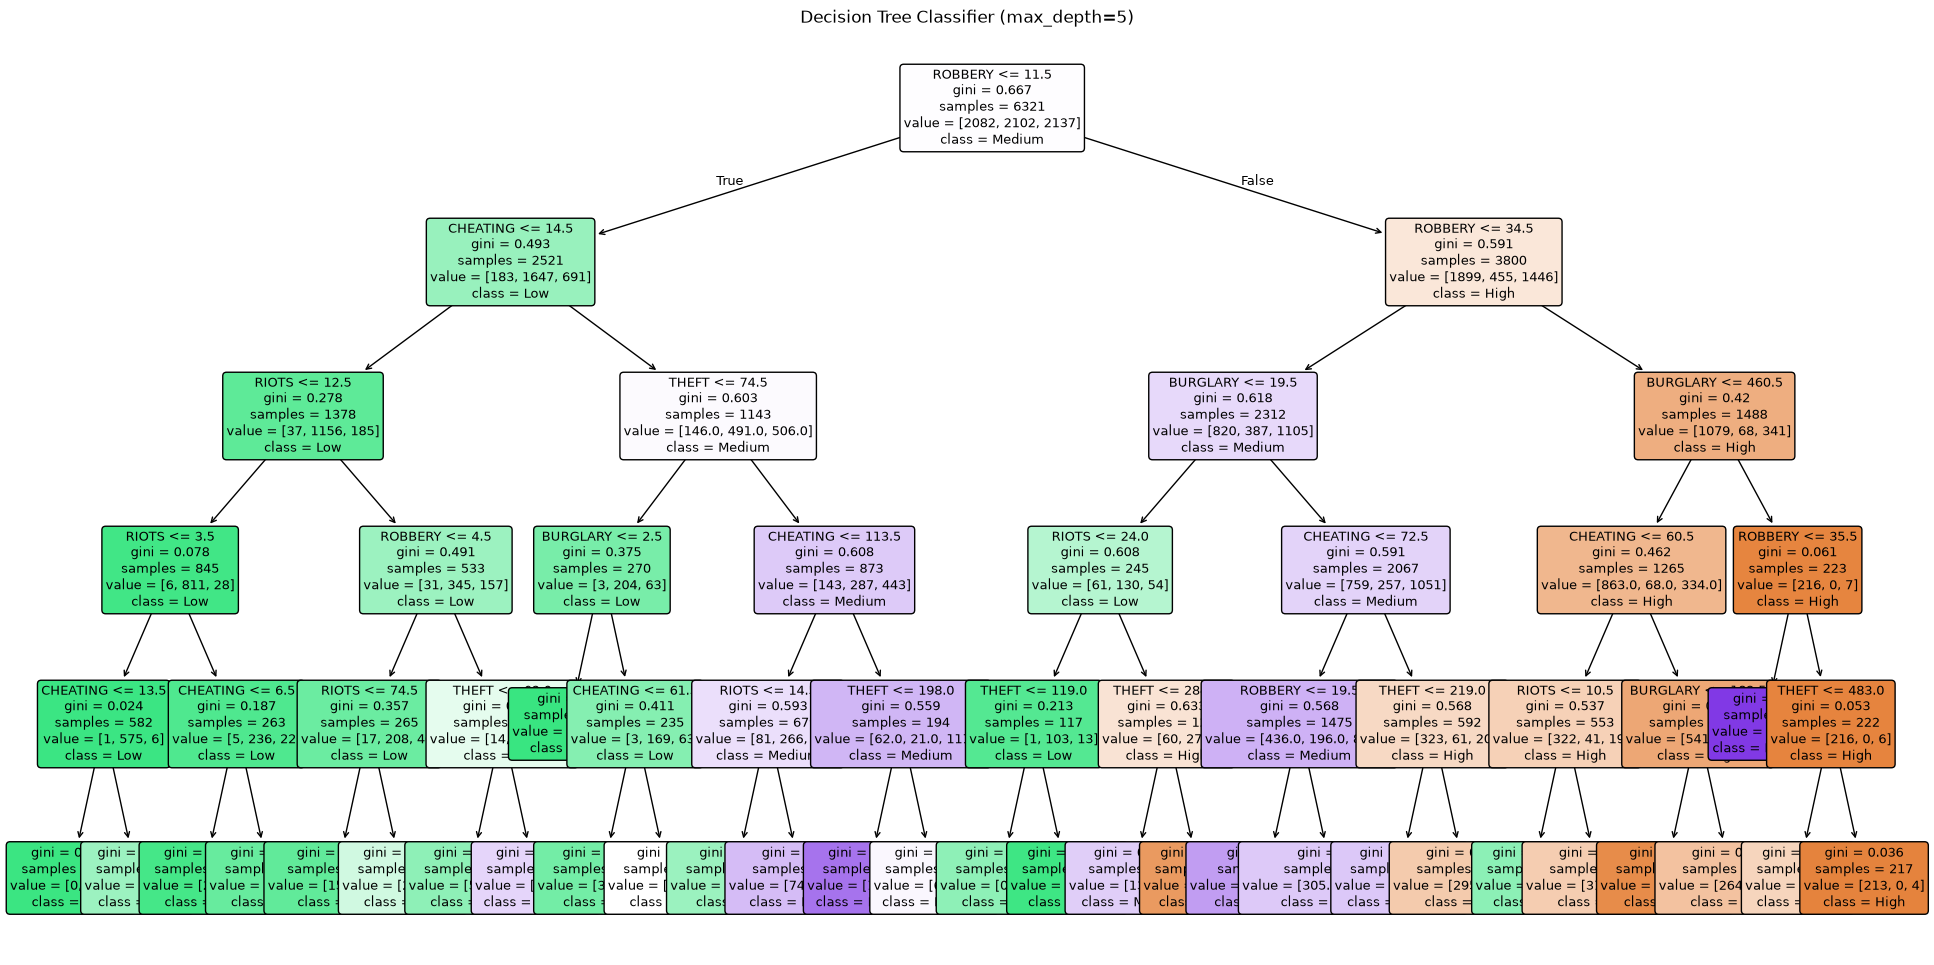

In [9]:
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X_train_clf.columns,
    class_names=list(model.classes_), # Needs to be a list for plot_tree
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Classifier (max_depth=5)")
plt.show()

## Step 11 — Analyze Prediction Examples

Let's combine our test features with the actual and predicted labels to see how individual districts were classified.

In [10]:
# Combine features, actual, and predicted for display
example_df = X_test_clf.copy()
example_df['Actual Level'] = y_test_clf.values
example_df['Predicted Level'] = y_pred

print("Sample Predictions:")
display(example_df.sample(15, random_state=42))

Sample Predictions:


,THEFT,BURGLARY,ROBBERY,CHEATING,RIOTS,Actual Level,Predicted Level
8792,224,66,12,226,3,Medium,High
8015,345,114,40,43,229,High,High
7533,125,57,36,73,288,High,High
7058,1615,642,145,255,437,High,High
7290,222,27,22,99,80,High,High
8038,126,64,27,61,70,Medium,Medium
7184,240,91,15,197,10,High,High
6665,269,122,6,117,0,Medium,Medium
6900,146,45,16,28,131,High,Medium
7897,470,162,80,57,142,High,High


## Model Interpretation

1. **What the model predicted:** The categorical `Violent Crime Level` (Low/Medium/High) of districts for the years 2010-2012.
2. **Features used:** Five distinct property and disturbance crimes (Theft, Burglary, Robbery, Cheating, Riots).
3. **How decisions were made:** The tree repeatedly split the districts based on crime counts. For example, it identified thresholds for Theft and Riots that cleanly separated High violent crime districts from Low violent crime districts.
4. **Evaluation metrics:** The model achieved a reasonable Accuracy and F1-score, proving that property crime profiles carry strong signals regarding violent crime profiles.
5. **Confusion Matrix Insights:** The matrix reveals that while the model struggles slightly to separate "Medium" from "High" or "Low" (making adjacent errors), it rarely confuses "Low" directly with "High", indicating it understands the extremes well.
6. **Feature Importance:** `THEFT` consistently emerges as a dominant splitting feature, likely because it is the most voluminous property crime and scales heavily with a district's overall size and activity.
7. **Tree Visualization:** The tree successfully learned that higher values across multiple property crimes logically funnel down into "High" violent crime predictions.

## Limitations

* **Custom Target:** The target is based on a project-defined Violent Crime Score rather than official classifications.
* **Historical Thresholds:** The Low/Medium/High thresholds were derived solely from the 2001-2009 period. If overall national crime surged in 2010, districts might artificially shift into "High" regardless of their relative local standing.
* **Absolute Counts:** The data contains absolute reported crime counts, not population-adjusted crime rates. "High" simply means high volume, not necessarily high per-capita danger.
* **Feature Selection:** Classification performance is heavily bounded by the 5 features we provided.
* **No Causation:** Historical crime patterns do not establish that one crime causes another.
* **Depth Limit:** We used `max_depth=5` to force simplicity and prevent overfitting. A deeper tree might be slightly more accurate but impossible to interpret on paper.

In [11]:
# Print final summary metrics
print("## Decision Tree Summary\n")
print("Model:              Decision Tree Classifier")
print("Target:             Violent Crime Level (Low/Medium/High)")
print("Features:           THEFT, BURGLARY, ROBBERY, CHEATING, RIOTS")
print("Training period:     2001 - 2009")
print("Testing period:      2010 - 2012")
print("Max depth:          5")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Weighted Precision: {precision:.4f}")
print(f"Weighted Recall:    {recall:.4f}")
print(f"Weighted F1-score:  {f1:.4f}\n")

print("Key Observations:")
print("1. The Decision Tree successfully classifies a significant majority of districts into their correct comparative crime level.")
print("2. The confusion matrix shows that severe misclassifications (predicting High when Actual is Low) are rare; most errors occur at the borders of Medium.")
print("3. Feature importance reveals that broad-volume crimes like Theft provide the strongest initial mathematical signals for categorizing overall district scale.")
print("4. Restricting max_depth to 5 prevented the model from memorizing the training data, allowing it to generalize well to the unseen 2010-2012 future period.")


## Decision Tree Summary

Model:              Decision Tree Classifier
Target:             Violent Crime Level (Low/Medium/High)
Features:           THEFT, BURGLARY, ROBBERY, CHEATING, RIOTS
Training period:     2001 - 2009
Testing period:      2010 - 2012
Max depth:          5
Accuracy:           0.6911
Weighted Precision: 0.6956
Weighted Recall:    0.6911
Weighted F1-score:  0.6931

Key Observations:
1. The Decision Tree successfully classifies a significant majority of districts into their correct comparative crime level.
2. The confusion matrix shows that severe misclassifications (predicting High when Actual is Low) are rare; most errors occur at the borders of Medium.
3. Feature importance reveals that broad-volume crimes like Theft provide the strongest initial mathematical signals for categorizing overall district scale.
4. Restricting max_depth to 5 prevented the model from memorizing the training data, allowing it to generalize well to the unseen 2010-2012 future period.


## Save Model for Streamlit

Saving the trained model and required preprocessing objects so they can be loaded by the Streamlit application.

In [12]:
import joblib
import os
os.makedirs('../models', exist_ok=True)
joblib.dump(model, "../models/decision_tree_model.joblib")

['../models/decision_tree_model.joblib']